# CEMBOT | Proyecto integrado — fases 1 y 2
**Una sola conversación: texto o fotografía opcional.** Fuente financiera: Excel exportado de SAP, **sin conexión directa a SAP**.

**Ejecución:** Ejecutar todas las celdas en orden. Cargar Excel en la sección 1 y ZIP de imágenes en la sección 5 (solo si se desea entrenar el modelo visual). El chat por texto no depende de las fotografías. Los importes proceden exclusivamente del Excel cargado. No se conservan métricas históricas como resultados de una ejecución nueva.

**Evidencias:** Las diez preguntas originales se preservan en la sección 3. NLP se evalúa en la sección 4; ResNet50 en la sección 5. La sección 6 ofrece la interfaz única. Para probar imágenes se requiere entrenar ResNet50 en la sesión o cargar un modelo propio compatible.

## 1. Preparación del entorno y carga de datos financieros

In [ ]:
import re, unicodedata, io, zipfile, hashlib, tempfile, os
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

def normalizar_texto(texto):
    texto = unicodedata.normalize('NFD', str(texto).lower().strip())
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]+', ' ', texto)).strip()

MESES = ['Enero','Febrero','Marzo','Abril','Mayo','Junio','Julio','Agosto','Septiembre','Octubre','Noviembre','Diciembre']
EQUIVALENCIAS_VISUALES = {'CUERPOS_MOLEDORES':'Cuerpos Moledores','LADRILLO_REFRACTARIO':'Ladrillo Refractario','PLACAS_Y_BLINDAJES':'Placas y Blindajes'}
SINONIMOS = {'energia hora punta':'Energía Eléctrica Punta','energia punta':'Energía Eléctrica Punta','electricidad punta':'Energía Eléctrica Punta','energia base':'Energía Eléctrica Base','electricidad base':'Energía Eléctrica Base'}

# Se puede ejecutar en Colab o en Python local si se dispone de un archivo Excel.
def cargar_finanzas(ruta_excel):
    libro = pd.ExcelFile(ruta_excel)
    if 'Ppto' not in libro.sheet_names:
        raise ValueError("Falta la hoja 'Ppto' en el Excel")
    anual = pd.read_excel(libro, sheet_name='Ppto', dtype={'Cuenta':str})
    anual.columns = anual.columns.astype(str).str.strip()
    requeridas = ['Cuenta','Clase de coste','Acumulado','Presupuesto','Saldo Ppto']
    faltantes = [c for c in requeridas if c not in anual]
    if faltantes: raise ValueError(f'Faltan columnas en Ppto: {faltantes}')
    anual = anual[requeridas].copy()
    for c in ['Cuenta','Clase de coste']:
        anual[c] = anual[c].astype('string').str.strip()
    for c in ['Acumulado','Presupuesto','Saldo Ppto']:
        anual[c] = pd.to_numeric(anual[c],errors='coerce')
    anual = anual.loc[anual['Cuenta'].notna() & (anual['Cuenta']!='*') & anual['Clase de coste'].notna()].copy()
    anual['Tiene presupuesto'] = anual['Presupuesto'].notna()
    anual['Saldo calculado'] = anual['Presupuesto'] - anual['Acumulado']
    anual['Diferencia saldo'] = anual['Saldo Ppto'] - anual['Saldo calculado']
    mensual = None
    if 'Costos variables' in libro.sheet_names:
        mensual = pd.read_excel(libro,sheet_name='Costos variables',dtype={'Cuenta':str})
        mensual.columns = mensual.columns.astype(str).str.strip()
        requeridas_mes = ['Cuenta','Clase de coste','Acumulado']+MESES
        faltantes_mes = [c for c in requeridas_mes if c not in mensual]
        if faltantes_mes: raise ValueError(f'Faltan columnas en Costos variables: {faltantes_mes}')
        mensual = mensual[requeridas_mes].copy()
        mensual['Cuenta'] = mensual['Cuenta'].astype('string').str.strip()
        mensual['Clase de coste'] = mensual['Clase de coste'].astype('string').str.strip()
        mensual = mensual.loc[mensual['Cuenta'].notna() & (mensual['Cuenta']!='*') & mensual['Clase de coste'].notna()].copy()
        for c in ['Acumulado']+MESES: mensual[c] = pd.to_numeric(mensual[c],errors='coerce')
        mensual['Suma mensual'] = mensual[MESES].sum(axis=1,min_count=1)
        mensual['Diferencia'] = mensual['Acumulado']-mensual['Suma mensual']
    return anual,mensual

# Solo esta celda solicita el Excel, una vez por sesión.
try:
    from google.colab import files
    print('Selecciona el Excel financiero exportado de SAP:')
    subidos = files.upload()
    if not subidos: raise RuntimeError('No se adjuntó un Excel financiero.')
    ruta_excel = next(iter(subidos))
except ImportError:
    ruta_excel = input('Ruta del Excel financiero: ').strip()

datos, base_mensual = cargar_finanzas(ruta_excel)
print('Registros anuales individuales:',len(datos))
print('Cuentas sin presupuesto:',int((~datos['Tiene presupuesto']).sum()))
print('Diferencias de saldo superiores a 0.05:',int((datos['Diferencia saldo'].abs()>0.05).sum()))
print('Registros mensuales:',0 if base_mensual is None else len(base_mensual))
display(datos.head())

Selecciona el Excel financiero exportado de SAP:


Saving costos_variables_consolidados.xlsx to costos_variables_consolidados (1).xlsx
Registros anuales individuales: 31
Cuentas sin presupuesto: 19
Diferencias de saldo superiores a 0.05: 0
Registros mensuales: 31


,Cuenta,Clase de coste,Acumulado,Presupuesto,Saldo Ppto,Tiene presupuesto,Saldo calculado,Diferencia saldo
0,56023001,Energía Eléctrica Base,7.102297e+06,25000000.0,17897702.89,True,17897702.89,0.0
1,56023002,5602 ENERGIA ELECTR.,2.247529e+07,25000000.0,2524714.68,True,2524714.68,0.0
2,56023003,Energía Eléctrica Punta,5.001382e+07,45000000.0,-5013816.01,True,-5013816.01,0.0
3,56043138,Aditivos,1.213095e+07,15000000.0,2869054.47,True,2869054.47,0.0
4,56033033,Coque,1.032869e+08,110000000.0,6713070.93,True,6713070.93,0.0


## 2. Motor financiero único y reconocimiento de cuentas

In [ ]:
def formato_importe(valor):
    return 'No disponible' if pd.isna(valor) else f'${float(valor):,.2f}'

def resolver_clase(texto, tabla=None):
    tabla = datos if tabla is None else tabla
    nombres = tabla['Clase de coste'].dropna().astype(str).unique().tolist()
    mapa = {normalizar_texto(n):n for n in nombres}
    consulta = normalizar_texto(texto)
    # Primero buscar nombres completos; evita confundir 'energía base' con 'energía punta'.
    halladas = {n for clave,n in mapa.items() if clave and re.search(r'(?<!\w)'+re.escape(clave)+r'(?!\w)',consulta)}
    if not halladas:
        for alias,destino in SINONIMOS.items():
            if re.search(r'(?<!\w)'+re.escape(alias)+r'(?!\w)',consulta):
                nombre = mapa.get(normalizar_texto(destino))
                if nombre: halladas.add(nombre)
    if len(halladas)==1: return next(iter(halladas)),None
    if len(halladas)>1: return None,'Encontré varias clases de coste. Especifica solo una.'
    # Admitir el nombre exacto pasado por otra función.
    nombre = mapa.get(consulta)
    return (nombre,None) if nombre else (None,'No identifiqué una clase de coste. Escribe ayuda para ver las disponibles.')

def registro_unico(clase, tabla=None):
    tabla = datos if tabla is None else tabla
    clave = normalizar_texto(clase)
    filas = tabla.loc[tabla['Clase de coste'].map(normalizar_texto)==clave]
    if len(filas)!=1:
        return None, f'No hay una cuenta única para {clase} (coincidencias: {len(filas)}).'
    return filas.iloc[0],None

def consultar_incurrido(clase):
    fila,error=registro_unico(clase)
    return error if error else f"{fila['Clase de coste']} — gasto acumulado anual 2026: {formato_importe(fila['Acumulado'])}."

def consultar_presupuesto(clase):
    fila,error=registro_unico(clase)
    if error:return error
    if not fila['Tiene presupuesto']:return f"{clase} no tiene presupuesto anual registrado."
    return f"{clase} — presupuesto anual 2026: {formato_importe(fila['Presupuesto'])}."

def consultar_saldo(clase):
    fila,error=registro_unico(clase)
    if error:return error
    if not fila['Tiene presupuesto']:return f"{clase} no tiene presupuesto anual registrado; no es posible calcular el saldo."
    return f"{clase} — saldo presupuestal calculado 2026: {formato_importe(fila['Saldo calculado'])}."

def consultar_cuentas_excedidas():
    excedidas = datos.loc[datos['Tiene presupuesto'] & (datos['Saldo calculado']<0)]
    if excedidas.empty:return 'No se identificaron cuentas con presupuesto registrado y saldo calculado negativo.'
    return 'Cuentas excedidas (con presupuesto registrado):\n'+'\n'.join(f"- {r['Clase de coste']}: {formato_importe(-r['Saldo calculado'])} excedido" for _,r in excedidas.iterrows())

def consultar_gasto_mensual(clase,mes):
    if base_mensual is None:return "No está disponible la hoja 'Costos variables'."
    fila,error=registro_unico(clase,base_mensual)
    if error:return error
    nombre=next((m for m in MESES if normalizar_texto(m)==normalizar_texto(mes)),None)
    if not nombre:return 'Mes no reconocido.'
    return f"{clase} — gasto de {nombre} 2026: {formato_importe(fila[nombre])}."

def consultar_acumulado_hasta_mes(clase,mes):
    if base_mensual is None:return "No está disponible la hoja 'Costos variables'."
    fila,error=registro_unico(clase,base_mensual)
    if error:return error
    nombre=next((m for m in MESES if normalizar_texto(m)==normalizar_texto(mes)),None)
    if not nombre:return 'Mes no reconocido.'
    periodo=MESES[:MESES.index(nombre)+1]
    importe=fila[periodo].sum(min_count=1)
    aviso=' Aviso: hay meses sin información.' if fila[periodo].isna().any() else ''
    if pd.notna(fila['Diferencia']) and abs(fila['Diferencia'])>0.01:
        aviso+=' Aviso: la suma mensual difiere del acumulado SAP.'
    return f'{clase} — acumulado calculado de enero a {nombre} 2026: {formato_importe(importe)}.'+aviso

def intencion_reglas(pregunta):
    t=normalizar_texto(pregunta)
    if re.search(r'\b(exced\w*|rebas\w*|sobrepas\w*|sobregasto|fuera de presupuesto)\b',t):return 'consultar_excedidos'
    if re.search(r'\b(saldo|disponible|restante|queda|resta|remanente)\b',t):return 'consultar_saldo'
    if re.search(r'\b(presupuesto|presupuestado|presupuestada)\b',t):return 'consultar_presupuesto'
    if re.search(r'\b(hasta|desde|entre)\b',t) and any(normalizar_texto(m) in t.split() for m in MESES):return 'consultar_acumulado_periodo'
    if any(normalizar_texto(m) in t.split() for m in MESES) and not re.search(r'\b(anual|ano)\b',t):return 'consultar_gasto_mensual'
    if re.search(r'\b(gasto|gastado|gastamos|incurrido|acumulado|costo|coste|anual|consumido|consumo|cuanto)\b',t):return 'consultar_gasto_anual'
    return None

def identificar_intencion_svm(pregunta):
    if 'modelo_cembot' not in globals():return None
    return str(modelo_cembot.predict([sustituir_entidades(pregunta)])[0])

def responder_cembot(pregunta):
    t=normalizar_texto(pregunta)
    if not t:return 'Escribe una pregunta sobre costos variables.'
    if t in {'hola','buenas','buenos dias','buenas tardes'}:return 'Hola. Puedes preguntarme por gasto acumulado, presupuesto o saldo, o adjuntar una fotografía.'
    if t in {'ayuda','lista','listar','clases de coste','que puedes hacer'}:
        return 'Clases disponibles:\n'+'\n'.join('- '+x for x in sorted(datos['Clase de coste'].dropna().astype(str).unique()))
    intencion=intencion_reglas(pregunta) or identificar_intencion_svm(pregunta)
    if intencion=='consultar_excedidos':return consultar_cuentas_excedidas()
    clase,error=resolver_clase(pregunta)
    if error:return error
    if intencion=='consultar_presupuesto':return consultar_presupuesto(clase)
    if intencion=='consultar_saldo':return consultar_saldo(clase)
    if intencion in {'consultar_gasto_mensual','consultar_acumulado_periodo'}:
        mes=next((m for m in MESES if normalizar_texto(m) in t.split()),None)
        if not mes:return 'Especifica el mes para consultar ese periodo.'
        return consultar_gasto_mensual(clase,mes) if intencion=='consultar_gasto_mensual' else consultar_acumulado_hasta_mes(clase,mes)
    if intencion=='consultar_gasto_anual':return consultar_incurrido(clase)
    return 'No comprendí la intención. Pregunta por gasto acumulado anual, presupuesto o saldo.'
print('Motor financiero preparado.')

Motor financiero preparado.


## 3. Evidencia de la primera entrega: diez conversaciones originales

In [ ]:
# =====================================================
# CEMBOT - EVIDENCIA FINAL DE 10 CONVERSACIONES
# =====================================================

conversaciones_finales = [
    "¿Cuánto hemos gastado en Coque?",
    "¿Cuál es el presupuesto de Aditivos?",
    "¿Cuánto queda disponible en Energía Eléctrica Base?",
    "¿Cuánto se ha incurrido en Arcilla?",
    "¿Qué cuentas excedieron el presupuesto?",
    "¿Cuánto queda disponible en energia hora punta?",
    "¿Cuánto gastamos en energia punta?",
    "¿Cuál es el presupuesto de Arcilla?",
    "¿Cuánto queda disponible en Placas y Blindajes?",
    "¿Cuánto hemos gastado en una cuenta inexistente?"
]

for numero, pregunta in enumerate(conversaciones_finales, 1):
    print(f"\n{'=' * 55}")
    print(f"CONVERSACIÓN {numero}")
    print("Gerente de Producción:", pregunta)
    print("CEMBOT:")
    print(responder_cembot(pregunta))

print(f"\nTotal de conversaciones ejecutadas: {len(conversaciones_finales)}")



CONVERSACIÓN 1
Gerente de Producción: ¿Cuánto hemos gastado en Coque?
CEMBOT:
Coque — gasto acumulado anual 2026: $103,286,929.07.

CONVERSACIÓN 2
Gerente de Producción: ¿Cuál es el presupuesto de Aditivos?
CEMBOT:
Aditivos — presupuesto anual 2026: $15,000,000.00.

CONVERSACIÓN 3
Gerente de Producción: ¿Cuánto queda disponible en Energía Eléctrica Base?
CEMBOT:
Energía Eléctrica Base — saldo presupuestal calculado 2026: $17,897,702.89.

CONVERSACIÓN 4
Gerente de Producción: ¿Cuánto se ha incurrido en Arcilla?
CEMBOT:
Arcilla — gasto acumulado anual 2026: $13,914,285.48.

CONVERSACIÓN 5
Gerente de Producción: ¿Qué cuentas excedieron el presupuesto?
CEMBOT:
Cuentas excedidas (con presupuesto registrado):
- Energía Eléctrica Punta: $5,013,816.01 excedido

CONVERSACIÓN 6
Gerente de Producción: ¿Cuánto queda disponible en energia hora punta?
CEMBOT:
Energía Eléctrica Punta — saldo presupuestal calculado 2026: $-5,013,816.01.

CONVERSACIÓN 7
Gerente de Producción: ¿Cuánto gastamos en energ

## 4. NLP supervisado — datos de entrenamiento, preprocesamiento, TF-IDF y SVM

In [ ]:
# ==========================================================
# CEMBOT - FASE 2
# PASO 1: CONJUNTO DE DATOS PARA CLASIFICAR INTENCIONES
# ==========================================================

import pandas as pd

# Ejemplos de entrenamiento creados para CEMBOT.
# Son expresiones de prueba, no conversaciones reales.

ejemplos = {
    "consultar_gasto_anual": [
        "¿Cuánto hemos gastado en coque?",
        "Dime el gasto acumulado de aditivos",
        "¿Cuál es el gasto anual de energía eléctrica punta?",
        "¿Cuánto se ha incurrido en arcilla?",
        "Muéstrame el gasto total de arenisca",
        "¿Cuál es el costo acumulado de yeso?",
        "Necesito consultar el gasto anual de coque",
        "¿Cuánto llevamos gastado en puzolana?"
    ],
    "consultar_presupuesto": [
        "¿Cuál es el presupuesto de coque?",
        "Dime el presupuesto anual de aditivos",
        "¿Qué presupuesto tiene energía eléctrica base?",
        "Consulta el presupuesto de arcilla",
        "¿Cuánto se presupuestó para arenisca?",
        "Muéstrame el presupuesto de coque",
        "Necesito conocer el presupuesto de yeso",
        "¿Cuál es el presupuesto asignado a aditivos?"
    ],
    "consultar_saldo": [
        "¿Cuánto queda disponible en coque?",
        "Dime el saldo del presupuesto de aditivos",
        "¿Qué presupuesto queda para energía eléctrica punta?",
        "Consulta la disponibilidad de arcilla",
        "¿Cuánto dinero queda en el presupuesto de coque?",
        "Muéstrame el saldo disponible de yeso",
        "¿Cuál es el presupuesto restante de aditivos?",
        "Necesito conocer el saldo de energía eléctrica base"
    ],
    "consultar_gasto_mensual": [
        "¿Cuánto gastamos en coque durante marzo?",
        "Dime el gasto de aditivos en febrero",
        "¿Cuál fue el costo de energía eléctrica punta en octubre?",
        "Consulta el gasto de arcilla en enero",
        "¿Cuánto se gastó en arenisca durante abril?",
        "Muéstrame el gasto mensual de coque en mayo",
        "Necesito el gasto de yeso correspondiente a junio",
        "¿Cuánto se incurrió en aditivos en septiembre?"
    ],
    "consultar_acumulado_periodo": [
        "¿Cuánto gastamos en coque hasta septiembre?",
        "Dime el acumulado de aditivos hasta agosto",
        "¿Cuál es el gasto acumulado de enero a marzo en coque?",
        "Consulta el gasto de arcilla hasta junio",
        "¿Cuánto se gastó de enero a octubre en arenisca?",
        "Muéstrame el acumulado hasta julio de yeso",
        "Necesito el gasto acumulado de coque hasta mayo",
        "¿Cuál es el gasto de enero a septiembre en aditivos?"
    ],
    "consultar_excedidos": [
        "¿Qué cuentas excedieron el presupuesto?",
        "Muéstrame las clases de coste con presupuesto excedido",
        "¿Cuáles son los costos que superaron el presupuesto?",
        "Dime qué partidas están excedidas",
        "¿Qué cuentas tienen saldo negativo?",
        "Consulta las clases de coste con sobregasto",
        "¿Dónde se excedió el presupuesto anual?",
        "Necesito conocer las cuentas fuera de presupuesto"
    ]
}

registros = [
    {"texto": frase, "intencion": intencion}
    for intencion, frases in ejemplos.items()
    for frase in frases
]

df_intenciones = pd.DataFrame(registros)

print("DATASET DE INTENCIONES CEMBOT")
print("-" * 45)
print("Total de ejemplos:", len(df_intenciones))
print("Intenciones definidas:", df_intenciones["intencion"].nunique())

print("\nEjemplos por intención:")
print(df_intenciones["intencion"].value_counts())

print("\nPrimeros registros:")
display(df_intenciones.head(10))

print("\nDuplicados:", df_intenciones["texto"].duplicated().sum())


DATASET DE INTENCIONES CEMBOT
---------------------------------------------
Total de ejemplos: 48
Intenciones definidas: 6

Ejemplos por intención:
intencion
consultar_gasto_anual          8
consultar_presupuesto          8
consultar_saldo                8
consultar_gasto_mensual        8
consultar_acumulado_periodo    8
consultar_excedidos            8
Name: count, dtype: int64

Primeros registros:


,texto,intencion
0,¿Cuánto hemos gastado en coque?,consultar_gasto_anual
1,Dime el gasto acumulado de aditivos,consultar_gasto_anual
2,¿Cuál es el gasto anual de energía eléctrica p...,consultar_gasto_anual
3,¿Cuánto se ha incurrido en arcilla?,consultar_gasto_anual
4,Muéstrame el gasto total de arenisca,consultar_gasto_anual
5,¿Cuál es el costo acumulado de yeso?,consultar_gasto_anual
6,Necesito consultar el gasto anual de coque,consultar_gasto_anual
7,¿Cuánto llevamos gastado en puzolana?,consultar_gasto_anual
8,¿Cuál es el presupuesto de coque?,consultar_presupuesto
9,Dime el presupuesto anual de aditivos,consultar_presupuesto



Duplicados: 0


In [ ]:
# ==========================================================
# CEMBOT - FASE 2
# PASO 4: AMPLIACIÓN DEL DATASET DE INTENCIONES
# ==========================================================

import pandas as pd

# Conservar los resultados originales como referencia
# La métrica inicial histórica no se reutiliza como resultado nuevo.

# Nuevas expresiones para cada intención
nuevos_ejemplos = {
    "consultar_gasto_anual": [
        "Dame el gasto total anual de coque",
        "¿Cuánto hemos consumido en aditivos este año?",
        "Consulta el importe anual de arcilla",
        "¿Cuál es el gasto total acumulado de yeso?",
        "Necesito el gasto incurrido del año para coque",
        "Muéstrame el costo anual de arenisca",
        "¿Cuánto se ha gastado en energía eléctrica base durante el año?",
        "Dime cuánto llevamos de gasto anual en puzolana"
    ],
    "consultar_presupuesto": [
        "Dame el presupuesto autorizado de coque",
        "¿Cuánto dinero se asignó a aditivos?",
        "Consulta el presupuesto aprobado de arcilla",
        "¿Cuál es el monto presupuestado para yeso?",
        "Necesito conocer el presupuesto total de arenisca",
        "Muéstrame el presupuesto original de coque",
        "¿Cuánto presupuesto tiene energía eléctrica base?",
        "Dime la cantidad presupuestada para puzolana"
    ],
    "consultar_saldo": [
        "Dame el saldo disponible de coque",
        "¿Cuánto presupuesto nos queda para aditivos?",
        "Consulta el remanente presupuestal de arcilla",
        "¿Qué cantidad queda por gastar en yeso?",
        "Necesito conocer la disponibilidad presupuestal de coque",
        "Muéstrame cuánto queda del presupuesto de arenisca",
        "¿Cuál es el saldo restante de energía eléctrica base?",
        "Dime cuánto dinero tenemos disponible para puzolana"
    ],
    "consultar_gasto_mensual": [
        "Dame el gasto de coque en enero",
        "¿Cuánto costaron los aditivos durante febrero?",
        "Consulta el consumo de arcilla en marzo",
        "¿Cuál fue el importe gastado en yeso en abril?",
        "Necesito el gasto correspondiente a mayo de coque",
        "Muéstrame cuánto gastamos en arenisca durante junio",
        "¿Cuál fue el gasto mensual de energía eléctrica punta en julio?",
        "Dime el costo registrado en agosto para puzolana"
    ],
    "consultar_acumulado_periodo": [
        "Dame el gasto de coque de enero a junio",
        "¿Cuánto acumulamos en aditivos hasta septiembre?",
        "Consulta el gasto de arcilla desde enero hasta abril",
        "¿Cuál es el importe acumulado de yeso hasta agosto?",
        "Necesito el total gastado de enero a octubre en coque",
        "Muéstrame el acumulado de arenisca hasta julio",
        "¿Cuánto se gastó entre enero y mayo en energía eléctrica base?",
        "Dime el gasto acumulado de puzolana hasta marzo"
    ],
    "consultar_excedidos": [
        "Dame las cuentas que rebasaron su presupuesto",
        "¿Qué clases de coste presentan sobregasto?",
        "Consulta las partidas que excedieron su límite presupuestal",
        "¿Cuáles son los conceptos con presupuesto insuficiente?",
        "Necesito identificar los costos fuera de presupuesto",
        "Muéstrame las cuentas con excedentes de gasto",
        "¿En qué clases de coste gastamos más de lo autorizado?",
        "Dime qué partidas superaron el presupuesto asignado"
    ]
}

# Crear DataFrame con los nuevos ejemplos
df_nuevos = pd.DataFrame([
    {"texto": pregunta, "intencion": intencion}
    for intencion, preguntas in nuevos_ejemplos.items()
    for pregunta in preguntas
])

# Unir con el dataset original
df_intenciones_ampliado = pd.concat(
    [
        df_intenciones[["texto", "intencion"]],
        df_nuevos
    ],
    ignore_index=True
)

# Eliminar duplicados exactos
df_intenciones_ampliado = (
    df_intenciones_ampliado
    .drop_duplicates(subset=["texto", "intencion"])
    .reset_index(drop=True)
)

print("DATASET AMPLIADO CEMBOT")
print("-" * 45)
print("Total de ejemplos:", len(df_intenciones_ampliado))
print("Intenciones:", df_intenciones_ampliado["intencion"].nunique())

print("\nEjemplos por intención:")
print(df_intenciones_ampliado["intencion"].value_counts())

print("\nDuplicados exactos de texto:",
      df_intenciones_ampliado["texto"].duplicated().sum())


DATASET AMPLIADO CEMBOT
---------------------------------------------
Total de ejemplos: 96
Intenciones: 6

Ejemplos por intención:
intencion
consultar_gasto_anual          16
consultar_presupuesto          16
consultar_saldo                16
consultar_gasto_mensual        16
consultar_acumulado_periodo    16
consultar_excedidos            16
Name: count, dtype: int64

Duplicados exactos de texto: 0


In [ ]:
# Tokenización, stopwords y stemming en español, sin depender de descargas de NLTK.
import nltk
from nltk.stem.snowball import SnowballStemmer
stemmer=SnowballStemmer('spanish')
STOPWORDS_ES={'de','del','la','las','el','los','en','un','una','por','para','que','me','mi','se','al','es','y','o','con','a','su','lo','cual','cuanto','cuantos','cuanta','cuantas'}
def preprocesar_texto(texto):
    tokens=nltk.wordpunct_tokenize(normalizar_texto(texto))
    return ' '.join(stemmer.stem(t) for t in tokens if t.isalpha() and t not in STOPWORDS_ES)
df_intenciones_ampliado['texto_procesado']=df_intenciones_ampliado['texto'].map(preprocesar_texto)
print('Ejemplos NLP:',len(df_intenciones_ampliado),'intenciones:',df_intenciones_ampliado['intencion'].nunique())
display(df_intenciones_ampliado[['texto','texto_procesado','intencion']].head())

Ejemplos NLP: 96 intenciones: 6


,texto,texto_procesado,intencion
0,¿Cuánto hemos gastado en coque?,hem gast coqu,consultar_gasto_anual
1,Dime el gasto acumulado de aditivos,dim gast acumul adit,consultar_gasto_anual
2,¿Cuál es el gasto anual de energía eléctrica p...,gast anual energi electr punt,consultar_gasto_anual
3,¿Cuánto se ha incurrido en arcilla?,ha incurr arcill,consultar_gasto_anual
4,Muéstrame el gasto total de arenisca,muestram gast total arenisc,consultar_gasto_anual


In [ ]:
# Sustitución de entidades a partir de ambas fuentes; independiente de la hoja mensual.
materiales=sorted({normalizar_texto(v) for v in datos['Clase de coste'].dropna().astype(str)} | ({normalizar_texto(v) for v in base_mensual['Clase de coste'].dropna().astype(str)} if base_mensual is not None else set()),key=len,reverse=True)
def sustituir_entidades(texto):
    t=normalizar_texto(texto)
    for material in materiales:
        if material:t=re.sub(r'(?<!\w)'+re.escape(material)+r'(?!\w)',' material ',t)
    for mes in MESES:t=re.sub(r'\b'+normalizar_texto(mes)+r'\b',' mes ',t)
    return re.sub(r'\s+',' ',t).strip()
df_intenciones_ampliado['texto_entidades']=df_intenciones_ampliado['texto'].map(sustituir_entidades)
display(df_intenciones_ampliado[['texto','texto_entidades','intencion']].head())

,texto,texto_entidades,intencion
0,¿Cuánto hemos gastado en coque?,cuanto hemos gastado en material,consultar_gasto_anual
1,Dime el gasto acumulado de aditivos,dime el gasto acumulado de material,consultar_gasto_anual
2,¿Cuál es el gasto anual de energía eléctrica p...,cual es el gasto anual de material,consultar_gasto_anual
3,¿Cuánto se ha incurrido en arcilla?,cuanto se ha incurrido en material,consultar_gasto_anual
4,Muéstrame el gasto total de arenisca,muestrame el gasto total de material,consultar_gasto_anual


EVALUACIÓN DEL CLASIFICADOR CEMBOT
Ejemplos de entrenamiento: 72
Ejemplos de prueba: 24
Intenciones: 6
Accuracy: 0.9583

REPORTE DE CLASIFICACIÓN
                             precision    recall  f1-score   support

consultar_acumulado_periodo       1.00      1.00      1.00         4
        consultar_excedidos       1.00      1.00      1.00         4
      consultar_gasto_anual       1.00      1.00      1.00         4
    consultar_gasto_mensual       1.00      1.00      1.00         4
      consultar_presupuesto       1.00      0.75      0.86         4
            consultar_saldo       0.80      1.00      0.89         4

                   accuracy                           0.96        24
                  macro avg       0.97      0.96      0.96        24
               weighted avg       0.97      0.96      0.96        24



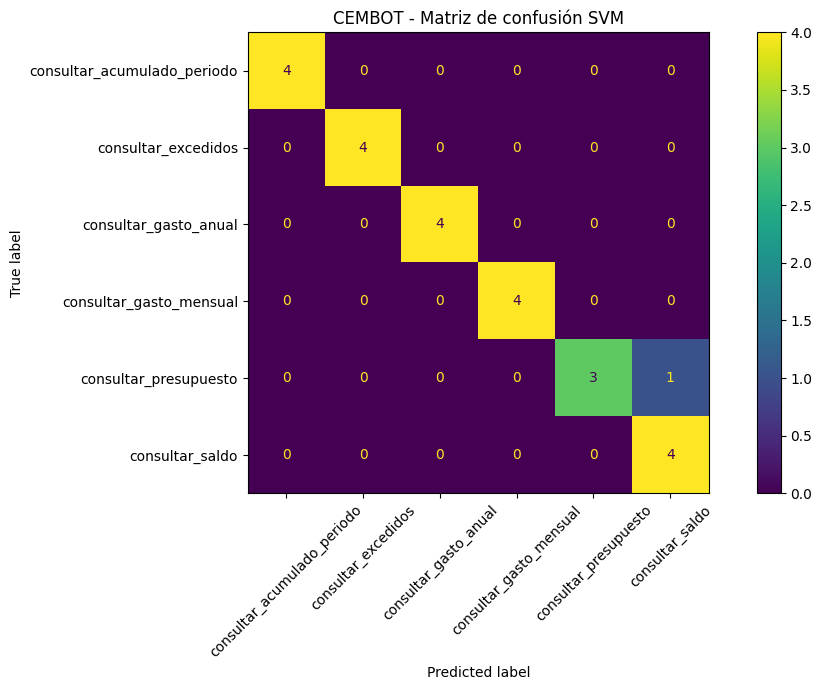


PREDICCIONES INDIVIDUALES


,Pregunta procesada,Intención real,Intención predicha,Correcta
0,necesito el gasto de material correspondiente ...,consultar_gasto_mensual,consultar_gasto_mensual,True
1,cuales son los conceptos con presupuesto insuf...,consultar_excedidos,consultar_excedidos,True
2,que cantidad queda por gastar en material,consultar_saldo,consultar_saldo,True
3,consulta el gasto de material hasta mes,consultar_acumulado_periodo,consultar_acumulado_periodo,True
4,que cuentas tienen saldo negativo,consultar_excedidos,consultar_excedidos,True
5,dame el gasto de material en mes,consultar_gasto_mensual,consultar_gasto_mensual,True
6,consulta el gasto de material desde mes hasta mes,consultar_acumulado_periodo,consultar_acumulado_periodo,True
7,necesito conocer el presupuesto total de material,consultar_presupuesto,consultar_saldo,False
8,dime el saldo del presupuesto de material,consultar_saldo,consultar_saldo,True
9,cual es el gasto total acumulado de material,consultar_gasto_anual,consultar_gasto_anual,True


In [ ]:
# ==========================================================
# CEMBOT - CLASIFICADOR DE INTENCIONES TF-IDF + SVM
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preparar preguntas e intenciones
X = df_intenciones_ampliado["texto_entidades"]
y = df_intenciones_ampliado["intencion"]

# 2. Separar entrenamiento y prueba
# Se mantienen las proporciones de las 6 intenciones.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 3. Crear pipeline de clasificación
modelo_cembot = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        C=1.0,
        random_state=42
    ))
])

# 4. Entrenar modelo
modelo_cembot.fit(X_train, y_train)

# 5. Predecir sobre preguntas de prueba
y_pred = modelo_cembot.predict(X_test)

# 6. Evaluar
accuracy_nlp = accuracy_score(y_test, y_pred)

print("EVALUACIÓN DEL CLASIFICADOR CEMBOT")
print("=" * 48)
print("Ejemplos de entrenamiento:", len(X_train))
print("Ejemplos de prueba:", len(X_test))
print("Intenciones:", y.nunique())
print(f"Accuracy: {accuracy_nlp:.4f}")
print()

print("REPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 7. Matriz de confusión
etiquetas = sorted(y.unique())

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=etiquetas
)

fig, ax = plt.subplots(figsize=(11, 7))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=etiquetas
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("CEMBOT - Matriz de confusión SVM")
plt.tight_layout()
plt.show()

# 8. Comparación de resultados individuales
resultados_svm = pd.DataFrame({
    "Pregunta procesada": X_test.values,
    "Intención real": y_test.values,
    "Intención predicha": y_pred,
    "Correcta": y_test.values == y_pred
})

print("\nPREDICCIONES INDIVIDUALES")
display(resultados_svm)

In [ ]:
# Pruebas de intención: el mismo preprocesamiento de entrenamiento se usa en inferencia.
for pregunta in ['¿Cuánto hemos gastado en Coque?','¿Cuál es el presupuesto de Aditivos?','¿Cuánto saldo queda de Coque?','¿Cuál fue el gasto de Coque en marzo?','¿Cuánto acumulamos en Arcilla hasta septiembre?','¿Qué cuentas excedieron el presupuesto?']:
    print(pregunta,'→',identificar_intencion_svm(pregunta))

¿Cuánto hemos gastado en Coque? → consultar_gasto_anual
¿Cuál es el presupuesto de Aditivos? → consultar_presupuesto
¿Cuánto saldo queda de Coque? → consultar_saldo
¿Cuál fue el gasto de Coque en marzo? → consultar_gasto_mensual
¿Cuánto acumulamos en Arcilla hasta septiembre? → consultar_acumulado_periodo
¿Qué cuentas excedieron el presupuesto? → consultar_excedidos


## 5. Componente visual — ResNet50 y evaluación
**Esta sección es opcional para consultas por texto.** Para habilitar fotografías, adjunta el ZIP original con las tres carpetas de categorías. El entrenamiento descarga pesos ImageNet si no están en caché. Si no tienes el ZIP, omite esta sección y ejecuta la sección 6 para consultas por texto.

In [ ]:
from collections import Counter,defaultdict
from PIL import Image
import hashlib
from sklearn.model_selection import train_test_split

ENTRENAR_VISUAL = True
dataset_visual = pd.DataFrame(columns=['ruta','categoria'])
if ENTRENAR_VISUAL:
    try:
        from google.colab import files
        print('Selecciona el ZIP de fotografías:')
        zips=files.upload()
        if not zips: raise RuntimeError('No se adjuntó ZIP.')
        archivo_zip=next(iter(zips))
    except ImportError:
        archivo_zip=input('Ruta del ZIP de imágenes: ').strip()
    destino=Path(tempfile.mkdtemp(prefix='cembot_imagenes_')).resolve()
    with zipfile.ZipFile(archivo_zip) as z:
        for item in z.infolist():
            ruta=Path(item.filename)
            if item.is_dir() or '__MACOSX' in ruta.parts or ruta.name.startswith('._') or ruta.name=='.DS_Store':continue
            final=(destino/ruta).resolve()
            if not final.is_relative_to(destino):raise ValueError('Ruta insegura en ZIP.')
            if final.suffix.lower() not in {'.png','.jpg','.jpeg'}:continue
            final.parent.mkdir(parents=True,exist_ok=True)
            with z.open(item) as origen,open(final,'wb') as salida:
                import shutil
                shutil.copyfileobj(origen,salida)
    registros=[]
    for ruta in destino.rglob('*'):
        if not ruta.is_file() or ruta.suffix.lower() not in {'.png','.jpg','.jpeg'}:continue
        try:
            with Image.open(ruta) as img:img.verify()
        except Exception:continue
        if ruta.parent.name in EQUIVALENCIAS_VISUALES:
            registros.append({'ruta':str(ruta),'categoria':ruta.parent.name,'hash':hashlib.sha256(ruta.read_bytes()).hexdigest()})
    dataset_visual=pd.DataFrame(registros)
    if dataset_visual.empty:raise ValueError('No hay imágenes válidas en las tres categorías esperadas.')
    # Evitar filtraciones de imágenes idénticas entre entrenamiento y prueba.
    dataset_visual=dataset_visual.drop_duplicates(subset='hash').reset_index(drop=True)
    if dataset_visual['categoria'].nunique()!=3 or dataset_visual['categoria'].value_counts().min()<4:
        raise ValueError('Se requieren imágenes suficientes en las tres categorías.')
    entrenamiento,temporal=train_test_split(dataset_visual,test_size=0.30,random_state=42,stratify=dataset_visual['categoria'])
    validacion,prueba=train_test_split(temporal,test_size=0.50,random_state=42,stratify=temporal['categoria'])
    assert not (set(entrenamiento['hash'])&set(validacion['hash']) or set(entrenamiento['hash'])&set(prueba['hash']) or set(validacion['hash'])&set(prueba['hash']))
    print('Imágenes únicas:',len(dataset_visual),'train/val/test:',len(entrenamiento),len(validacion),len(prueba))
    display(dataset_visual['categoria'].value_counts())
else:
    print('Entrenamiento visual omitido. El chat por texto sigue disponible.')

Selecciona el ZIP de fotografías:


Saving CEMBOT_IMAGENES.zip to CEMBOT_IMAGENES.zip
Imágenes únicas: 98 train/val/test: 68 15 15


,count
categoria,
PLACAS_Y_BLINDAJES,44
LADRILLO_REFRACTARIO,35
CUERPOS_MOLEDORES,19


In [ ]:
if ENTRENAR_VISUAL:

    # ==========================================================
    # CEMBOT - COMPONENTE VISUAL
    # PASO 4: ENTRENAMIENTO CON RESNET50
    # ==========================================================

    import numpy as np
    import tensorflow as tf
    from tensorflow.keras.applications import ResNet50
    from tensorflow.keras.applications.resnet50 import preprocess_input
    from tensorflow.keras import layers, Model
    from sklearn.preprocessing import LabelEncoder

    # Configuración reproducible
    tf.keras.utils.set_random_seed(42)
    TAMANO = (224, 224)
    BATCH = 8

    # Codificar las tres categorías
    codificador_visual = LabelEncoder()
    codificador_visual.fit(dataset_visual["categoria"])

    clases_visuales = list(codificador_visual.classes_)
    print("Categorías:", clases_visuales)

    # Preparar imágenes y etiquetas
    def crear_dataset(tabla, mezclar=False):
        rutas = tabla["ruta"].astype(str).to_numpy()
        etiquetas = codificador_visual.transform(
            tabla["categoria"]
        )

        ds = tf.data.Dataset.from_tensor_slices(
            (rutas, etiquetas)
        )

        def procesar(ruta, etiqueta):
            imagen = tf.io.read_file(ruta)
            imagen = tf.io.decode_image(
                imagen, channels=3, expand_animations=False
            )
            imagen.set_shape([None, None, 3])
            imagen = tf.image.resize(imagen, TAMANO)
            imagen = preprocess_input(imagen)
            return imagen, etiqueta

        ds = ds.map(
            procesar,
            num_parallel_calls=tf.data.AUTOTUNE
        )

        if mezclar:
            ds = ds.shuffle(
                len(tabla), seed=42,
                reshuffle_each_iteration=True
            )

        return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

    ds_entrenamiento = crear_dataset(entrenamiento, True)
    ds_validacion = crear_dataset(validacion)
    ds_prueba = crear_dataset(prueba)

    # Transferencia de aprendizaje con ResNet50
    base_visual = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base_visual.trainable = False

    entrada = layers.Input(shape=(224, 224, 3))
    x = base_visual(entrada, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    salida = layers.Dense(
        len(clases_visuales),
        activation="softmax"
    )(x)

    modelo_visual = Model(entrada, salida)

    modelo_visual.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Detener entrenamiento si deja de mejorar
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    # Entrenar el clasificador
    historial_visual = modelo_visual.fit(
        ds_entrenamiento,
        validation_data=ds_validacion,
        epochs=20,
        callbacks=[parada_temprana],
        verbose=1
    )

    print("\nENTRENAMIENTO RESNET50 FINALIZADO")
else:
    print('Modelo visual no entrenado en esta sesión.')

Categorías: ['CUERPOS_MOLEDORES', 'LADRILLO_REFRACTARIO', 'PLACAS_Y_BLINDAJES']
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.4559 - loss: 1.3829 - val_accuracy: 0.5333 - val_loss: 1.2950
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5735 - loss: 1.2039 - val_accuracy: 0.4667 - val_loss: 1.2549
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5294 - loss: 1.2896 - val_accuracy: 0.5333 - val_loss: 1.2572
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5735 - loss: 1.1859 - val_accuracy: 0.5333 - val_loss: 1.2248
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.5441 - loss: 1.0214 - val_accuracy: 0.5333 - val_loss: 1.1793
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6176 - loss: 1.0711 - val_accuracy: 0.5333 - val_loss: 1.1543
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5882 - loss: 1.1028 - val_accuracy: 0.6000 - val_loss: 1.1384
E

EVALUACIÓN DEL CLASIFICADOR VISUAL CEMBOT
Accuracy:  0.6667
Precision: 0.4464
Recall:    0.5556
F1-score:  0.4945

REPORTE DE CLASIFICACIÓN
                      precision    recall  f1-score   support

   CUERPOS_MOLEDORES       0.00      0.00      0.00         3
LADRILLO_REFRACTARIO       0.71      0.83      0.77         6
  PLACAS_Y_BLINDAJES       0.62      0.83      0.71         6

            accuracy                           0.67        15
           macro avg       0.45      0.56      0.49        15
        weighted avg       0.54      0.67      0.59        15



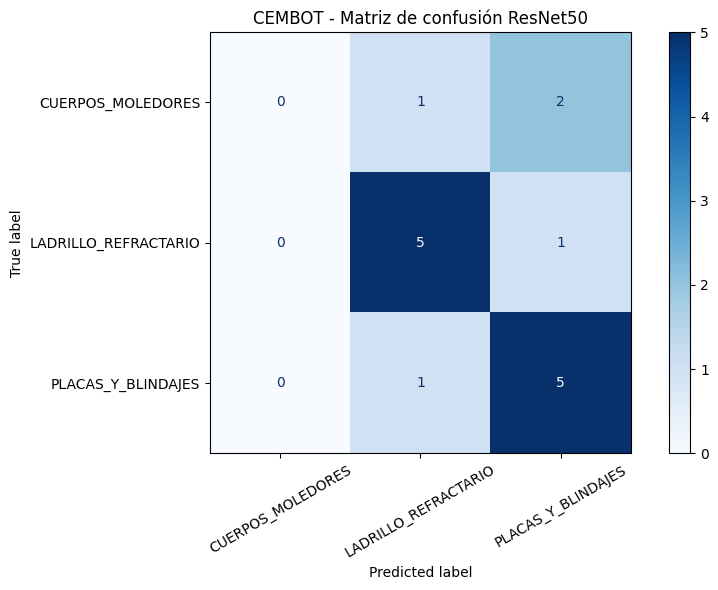


PREDICCIONES INDIVIDUALES


,categoria,Predicción,Correcta
0,CUERPOS_MOLEDORES,LADRILLO_REFRACTARIO,False
1,LADRILLO_REFRACTARIO,LADRILLO_REFRACTARIO,True
2,PLACAS_Y_BLINDAJES,PLACAS_Y_BLINDAJES,True
3,CUERPOS_MOLEDORES,PLACAS_Y_BLINDAJES,False
4,PLACAS_Y_BLINDAJES,LADRILLO_REFRACTARIO,False
5,PLACAS_Y_BLINDAJES,PLACAS_Y_BLINDAJES,True
6,LADRILLO_REFRACTARIO,LADRILLO_REFRACTARIO,True
7,PLACAS_Y_BLINDAJES,PLACAS_Y_BLINDAJES,True
8,PLACAS_Y_BLINDAJES,PLACAS_Y_BLINDAJES,True
9,LADRILLO_REFRACTARIO,PLACAS_Y_BLINDAJES,False


In [ ]:
if ENTRENAR_VISUAL:
    # ==========================================================
    # CEMBOT - COMPONENTE VISUAL
    # PASO 5: EVALUACIÓN DEL CLASIFICADOR RESNET50
    # ==========================================================

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        classification_report,
        confusion_matrix,
        ConfusionMatrixDisplay
    )

    # Etiquetas reales del conjunto de prueba
    y_real = codificador_visual.transform(
        prueba["categoria"]
    )

    # Predicciones del modelo
    probabilidades = modelo_visual.predict(
        ds_prueba,
        verbose=0
    )

    y_predicho = np.argmax(probabilidades, axis=1)

    # Calcular métricas globales
    accuracy_visual = accuracy_score(y_real, y_predicho)
    precision = precision_score(
        y_real, y_predicho,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_real, y_predicho,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        y_real, y_predicho,
        average="macro", zero_division=0
    )

    print("EVALUACIÓN DEL CLASIFICADOR VISUAL CEMBOT")
    print("=" * 50)

    print(f"Accuracy:  {accuracy_visual:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

    print("\nREPORTE DE CLASIFICACIÓN")
    print(classification_report(
        y_real,
        y_predicho,
        labels=range(len(clases_visuales)),
        target_names=clases_visuales,
        zero_division=0
    ))

    # Matriz de confusión
    matriz = confusion_matrix(
        y_real,
        y_predicho,
        labels=range(len(clases_visuales))
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=clases_visuales
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=30
    )

    plt.title("CEMBOT - Matriz de confusión ResNet50")
    plt.tight_layout()
    plt.show()

    # Resultados individuales
    resultados_visuales = prueba.copy().reset_index(drop=True)

    resultados_visuales["Predicción"] = (
        codificador_visual.inverse_transform(y_predicho)
    )

    resultados_visuales["Correcta"] = (
        y_real == y_predicho
    )

    print("\nPREDICCIONES INDIVIDUALES")
    display(resultados_visuales[
        ["categoria", "Predicción", "Correcta"]
    ])
else:
    print('Sin evaluación visual nueva: no se entrenó ResNet50.')

In [ ]:
# Comprobaciones automáticas de arquitectura financiera y de las diez preguntas.
assert len(conversaciones_finales)==10
assert all(isinstance(responder_cembot(p),str) and responder_cembot(p).strip() for p in conversaciones_finales)
assert 'gasto acumulado anual' in responder_cembot('¿Cuál es el costo acumulado anual de Coque?').lower()
assert 'presupuesto' in responder_cembot('¿Cuál es el presupuesto de Aditivos?').lower()
assert identificar_intencion_svm('¿Cuánto acumulamos en Arcilla hasta septiembre?') in set(df_intenciones_ampliado['intencion'])
print('Pruebas automáticas de consultas y NLP: correctas. No validan ResNet50 sin fotografías.')

Pruebas automáticas de consultas y NLP: correctas. No validan ResNet50 sin fotografías.


## 6. Interfaz conversacional única: pregunta escrita o fotografía opcional

In [ ]:
import ipywidgets as widgets
from IPython.display import display
from PIL import Image

def analizar_imagen_cembot(contenido):
    if 'modelo_visual' not in globals() or 'clases_visuales' not in globals():
        return None,None,'Primero entrena ResNet50 en la sección 5 para habilitar fotografías. Las preguntas por texto siguen disponibles.'
    from tensorflow.keras.applications.resnet50 import preprocess_input
    from tensorflow.keras.utils import img_to_array
    with Image.open(io.BytesIO(contenido)) as img:
        imagen=img.convert('RGB').resize((224,224))
    entrada=preprocess_input(np.expand_dims(img_to_array(imagen),axis=0))
    probabilidades=modelo_visual.predict(entrada,verbose=0)[0]
    indice=int(np.argmax(probabilidades))
    return clases_visuales[indice],float(probabilidades[indice]),None

def responder_imagen(contenido):
    categoria,confianza,error=analizar_imagen_cembot(contenido)
    if error:return error
    clase=EQUIVALENCIAS_VISUALES.get(categoria)
    if not clase:return 'La categoría predicha no tiene equivalencia financiera.'
    # La confianza no está calibrada: pedir confirmación ante incertidumbre.
    if confianza<0.70:
        return f'Identificación tentativa: {clase} (confianza {confianza:.1%}). Confirma el nombre del material antes de atribuirle un gasto.'
    return f'Material identificado: {clase} (confianza {confianza:.1%}).\n'+consultar_incurrido(clase)+'\nVerifica que el material haya sido identificado correctamente.'

salida=widgets.Output(layout=widgets.Layout(border='1px solid #ddd',height='300px',overflow_y='auto'))
entrada=widgets.Text(placeholder='¿Cuál es el gasto acumulado anual de Coque?',layout=widgets.Layout(width='75%'))
enviar=widgets.Button(description='Enviar',button_style='primary')
foto=widgets.FileUpload(accept='image/*',multiple=False,description='Adjuntar foto')
def mostrar(autor,mensaje):
    with salida:print(f'{autor}: {mensaje}\n')
def enviar_texto(_):
    pregunta=entrada.value.strip()
    if not pregunta:return
    entrada.value=''
    mostrar('Usuario',pregunta)
    try:mostrar('CEMBOT',responder_cembot(pregunta))
    except Exception as e:mostrar('CEMBOT',f'No se pudo responder: {e}')
def recibir_foto(cambio):
    subida=cambio['new']
    if not subida:return
    archivo=next(iter(subida.values())) if isinstance(subida,dict) else subida[0]
    contenido=archivo['content'] if isinstance(archivo,dict) else archivo.content
    nombre=archivo.get('name','fotografía') if isinstance(archivo,dict) else archivo.name
    mostrar('Usuario',f'[Imagen: {nombre}]')
    try:mostrar('CEMBOT',responder_imagen(bytes(contenido)))
    except Exception as e:mostrar('CEMBOT',f'No se pudo analizar la imagen: {e}')
enviar.on_click(enviar_texto)
foto.observe(recibir_foto,names='value')
display(widgets.VBox([salida,widgets.HBox([entrada,enviar]),foto]))
mostrar('CEMBOT','Hola. Puedes escribir una pregunta financiera o adjuntar una fotografía.')

## 7. Validación y limitaciones
- Las diez preguntas de la primera entrega se ejecutan sin imágenes.
- El acumulado **anual** procede de `Ppto.Acumulado` y no se sustituye por la suma mensual.
- Las consultas de presupuesto sin dato no se interpretan como presupuesto cero.
- La evaluación visual solo es válida si se ejecuta el entrenamiento con imágenes reales; no se inventan resultados.
- Una predicción visual no garantiza la identidad del material. Ante confianza baja se solicita confirmación.
- Ejecutar desde una sesión nueva de Colab requiere volver a cargar el Excel y, si se necesitan fotografías, entrenar o restaurar un modelo visual.